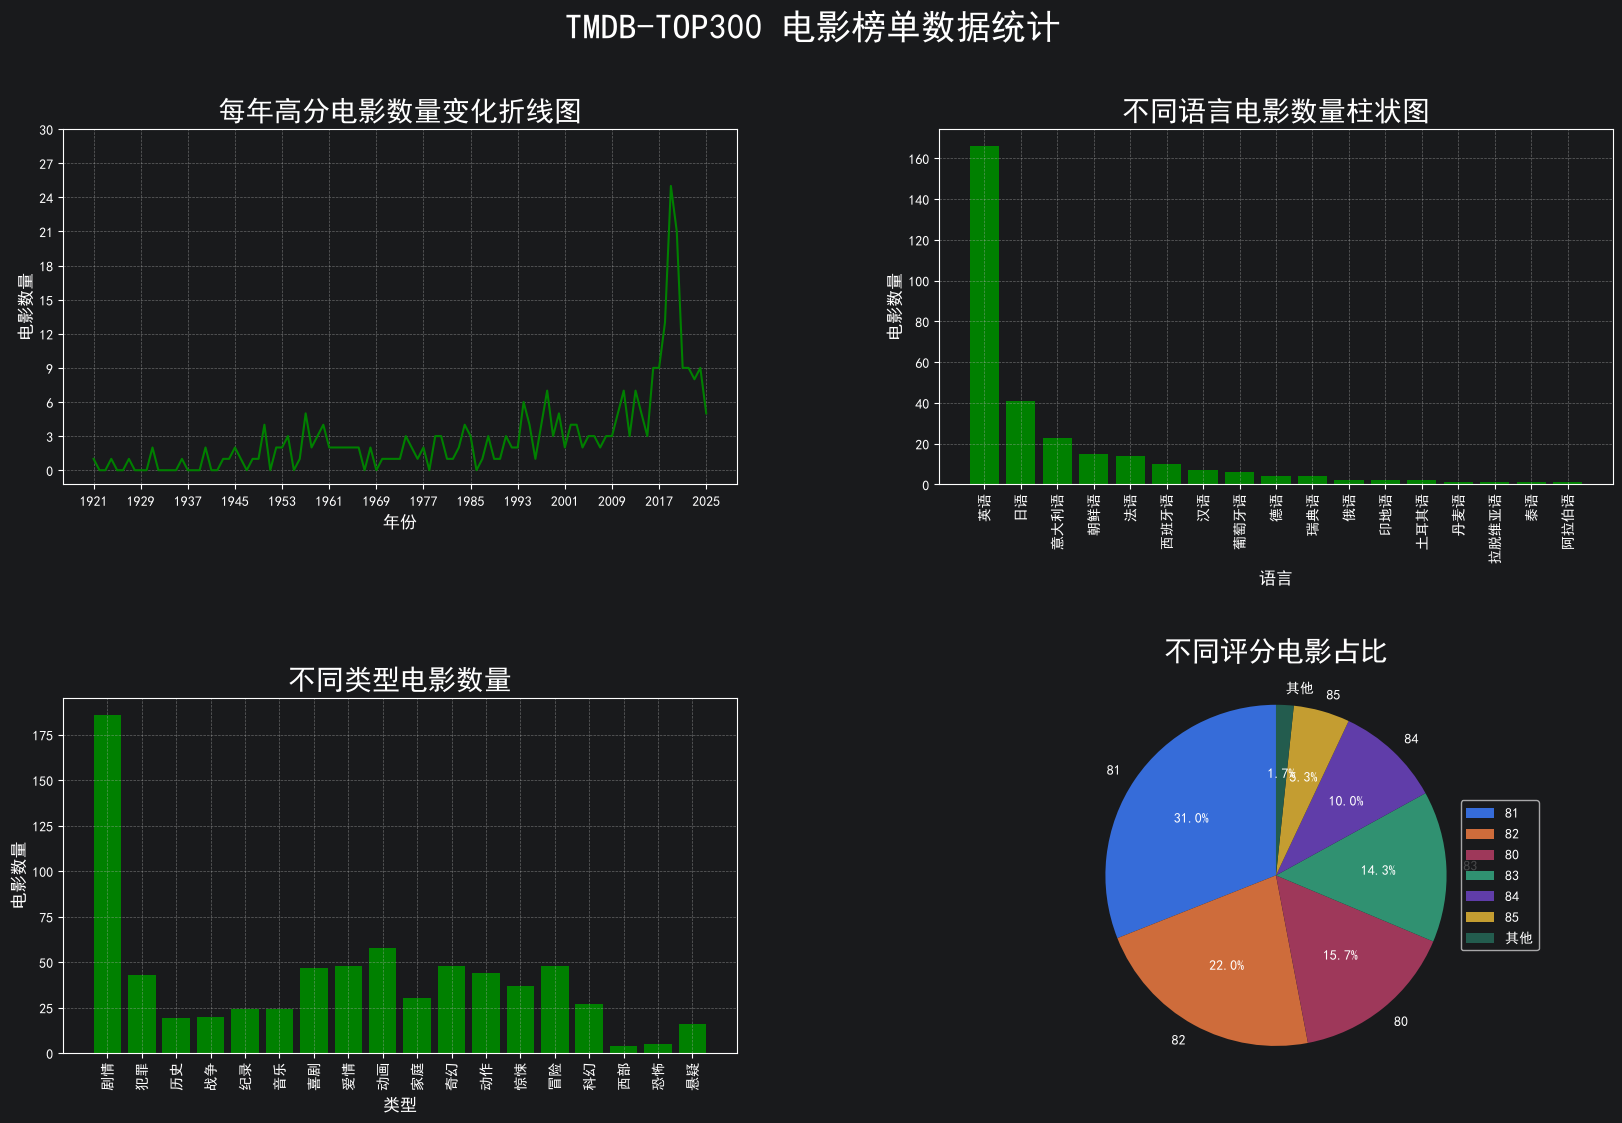

In [1]:
from matplotlib.axes import Axes
import pandas as pd
import matplotlib.pyplot as plt

#展示中文
plt.rcParams['font.sans-serif'] = ['SimHei']

#创建子图
figure,axes = plt.subplots(nrows=2, ncols=2, figsize=(20,12),dpi=100)
figure.suptitle('TMDB-TOP300 电影榜单数据统计',fontsize=25,x=0.5,y=0.98)
figure.subplots_adjust(hspace=0.6,wspace=0.3)
axes1: Axes = axes[0,0]
axes2: Axes = axes[0,1]
axes3: Axes = axes[1,0]
axes4: Axes = axes[1,1]

#加载数据
#int 64: 整型数字(不支持空值)
#Int64: 整型数字(支持空值)
#float64 :浮点型数字(支持空值)
data = pd.read_csv('C:\\Users\\LENOVO\\Desktop\\movies.csv',usecols=['电影名','年份','上映时间','类型','时长','评分','语言'],dtype={'年份':'Int64'})
data


#1.需求一:统计TOP三百的电影中，每一年上瘾的电影数量的变化 (折线图)
#1.1 缺失值处理
data.isnull().sum()  #false计0，true计1,相加求和即为缺失值数量
data['年份'] = data['年份'].fillna(data['上映时间'].str[0:4:1])

#1.2 分组统计
year_count = data.groupby('年份')['年份'].count()

#1.3组装数据
#x组数据
min_year = year_count.index.min()
max_year = year_count.index.max()
x=[i for i in range(min_year,max_year+1)]

#y组数据
y=[int(year_count.get(i,0)) for i in x]
#1.4 绘制折线图
axes1.plot(x,y,color='green')
axes1.set_title('每年高分电影数量变化折线图',fontsize=20)
axes1.set_xlabel('年份',fontsize=12)
axes1.set_ylabel('电影数量',fontsize=12)

axes1.set_xticks(x[::8])  #设置X轴刻度的间隔
y_ticks=[i for i in range(0,31,3)]
axes1.set_yticks(y_ticks)   #设置Y轴刻度的间隔
axes1.grid(linestyle='--',alpha=0.5)


#需求二： 统计TOP300的电影中，不同语言电影的数量(柱状图)
#2.1获取不同语言对应的电影数量
language_count = data.groupby('语言')['语言'].count().sort_values(ascending=False)

x_language = language_count.index.tolist()
y_language_count = language_count.values.tolist()
#2.2 绘制柱状图
axes2.bar(x_language,y_language_count,color='green',width=0.8)
axes2.set_title('不同语言电影数量柱状图',fontsize=20)
axes2.set_xlabel('语言',fontsize=12)
axes2.set_ylabel('电影数量',fontsize=12)
axes2.grid(linestyle='--',alpha=0.5)
axes2.tick_params(axis='x', rotation=90)


#需求三 统计不同类型电影数量
#3.1 获取不同类型电影的数量
type_count = {}
for types in data['类型'].str.split(','):
    for type in types:
        if type in type_count:
            type_count[type] += 1
        else:
            type_count[type] = 1
x_type = type_count.keys()
y_type = type_count.values()

#3.2绘制柱状图
axes3.bar(x_type,y_type,color='green')
axes3.set_title('不同类型电影数量',fontsize=20)
axes3.set_xlabel('类型',fontsize=12)
axes3.set_ylabel('电影数量',fontsize=12)
axes3.grid(linestyle='--',alpha=0.5)
axes3.tick_params(axis='x', rotation=90)


#需求四 统计对比哥哥评分的电影占比 （饼状图）
# 4.1 获取不同评分的电影数量
score_count = data.groupby('评分')['评分'].count().sort_values(ascending=False)

#合并小数据（比例小于百分之二）--> 其他
total = score_count.sum()
large_scores = score_count.loc[score_count>=total*0.02] #大数据
small_scores = score_count.loc[score_count<total*0.02] #小数据

if small_scores.shape[0]>0:
    large_scores['其他']=small_scores.sum()

scores = large_scores.index.tolist()
scores_values = large_scores.values.tolist()

#4.2  绘制饼状图
axes4.pie(scores_values,labels=scores,autopct='%1.1f%%',shadow=False,startangle=90,radius=1.2)
axes4.set_title('不同评分电影占比',fontsize=20,y=1.08)
axes4.legend(loc='center left', bbox_to_anchor=(1, 0.5))

#5 保存图片
plt.savefig('TMDB-TOP300.png')


plt.show()

In [19]:
print(data[['年份', '上映时间']].head(10))

print(data['年份'].dtype)
print(data['上映时间'].dtype)
print(data['年份'].isnull().sum())
print(data['上映时间'].isnull().sum())
print(data['上映时间'].head(10).tolist())
year_str = []
year_str = data['上映时间'].str[0:4]
print(year_str.head())
print(year_str.dtype)
year_int = year_str.astype('int64')
print(year_int)
print(year_int.dtype)
data['年份'] = year_int
print(data['年份'].dtype)
print(data[['年份', '上映时间']].head())


     年份        上映时间
0  1994  1994-09-23
1  1972  1972-03-24
2  1974  1974-12-20
3  2019  2019-04-06
4  1957  1957-04-10
5  2022  2022-11-02
6  2023  2023-09-21
7  2019  2019-06-21
8  2018  2018-04-07
9  1995  1995-10-20
int64
object
0
0
['1994-09-23', '1972-03-24', '1974-12-20', '2019-04-06', '1957-04-10', '2022-11-02', '2023-09-21', '2019-06-21', '2018-04-07', '1995-10-20']
0    1994
1    1972
2    1974
3    2019
4    1957
Name: 上映时间, dtype: object
object
0      1994
1      1972
2      1974
3      2019
4      1957
       ... 
295    2021
296    2015
297    2009
298    2018
299    1949
Name: 上映时间, Length: 300, dtype: int64
int64
int64
     年份        上映时间
0  1994  1994-09-23
1  1972  1972-03-24
2  1974  1974-12-20
3  2019  2019-04-06
4  1957  1957-04-10
